# Spotify Audio Features × Billboard Hot 100

## Questions
1. How do audio features differ across chart decades in the matched Spotify sample?
2. Do recordings reaching the Top 10 differ from those peaking at 51–100?
3. Which genres are most common in the matched sample, and how do their features differ?
4. Which recordings have low valence and high snapshot popularity, or a slow tempo and a Top 10 peak?

Install the requirements once, then run this notebook from top to bottom in Jupyter.
Data preparation is in the project's src folder. This notebook contains the analysis, static plots and Key findings.


In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").is_dir():
    raise RuntimeError("Start Jupyter from the project folder containing src/ and notebooks/.")
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data
from src.cleaning import clean_spotify, clean_hot100
from src.matching import match_songs

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 6)
pd.set_option("display.max_columns", 50)


## 1) Load datasets

Reuse CSVs from the project's data folder. If they are missing, the loader tries the existing Drive mirrors and extracts the two required CSVs. See the README for original sources and manual download instructions.


In [2]:
spotify_raw, hot100_raw = load_data(PROJECT_ROOT / "data")


Downloading...
From: https://drive.google.com/uc?id=1KvG1T9rL6gOqmOO-VDOpO4PhKUdFU2Lh
To: C:\Users\Anna\Downloads\Spotify_Billboard_GitHub\spotify_billboard\data\SpotifyFeatures.zip
100%|██████████| 16.2M/16.2M [00:00<00:00, 19.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1iqefQOCEMdTs4lKZTguRexnGYi0TWCHO
To: C:\Users\Anna\Downloads\Spotify_Billboard_GitHub\spotify_billboard\data\hot-100-current.zip
100%|██████████| 3.36M/3.36M [00:00<00:00, 12.2MB/s]


## 2) Preview the inputs


In [3]:
print("Spotify shape:", spotify_raw.shape)
print("Hot100 shape :", hot100_raw.shape)
display(spotify_raw.head(3))
display(hot100_raw.head(3))


Spotify shape: (232725, 18)
Hot100 shape : (343600, 7)


,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
0,Movie,Henri Salvador,C'est beau de faire un Show,0BRjO6ga9RKCKjfDqeFgWV,0,0.611,0.389,99373,0.910,0.0,C#,0.346,-1.828,Major,0.0525,166.969,4/4,0.814
1,Movie,Martin & les fées,Perdu d'avance (par Gad Elmaleh),0BjC1NfoEOOusryehmNudP,1,0.246,0.590,137373,0.737,0.0,F#,0.151,-5.559,Minor,0.0868,174.003,4/4,0.816
2,Movie,Joseph Williams,Don't Let Me Be Lonely Tonight,0CoSDzoNIKCRs124s9uTVy,3,0.952,0.663,170267,0.131,0.0,C,0.103,-13.879,Minor,0.0362,99.488,5/4,0.368


,chart_week,current_week,title,performer,last_week,peak_pos,wks_on_chart
0,2022-01-01,1,All I Want For Christmas Is You,Mariah Carey,1.0,1,50
1,2022-01-01,2,Rockin' Around The Christmas Tree,Brenda Lee,2.0,2,44
2,2022-01-01,3,Jingle Bell Rock,Bobby Helms,4.0,3,41


## 3) Quick overview
Inspect the column names and missing values in both datasets.


In [4]:
print("Spotify columns:", spotify_raw.columns.tolist())
print("Hot100 columns :", hot100_raw.columns.tolist())

print("\nSpotify missing values (top):")
display(spotify_raw.isna().sum().sort_values(ascending=False).head(15))

print("\nHot100 missing values (top):")
display(hot100_raw.isna().sum().sort_values(ascending=False).head(15))


Spotify columns: ['genre', 'artist_name', 'track_name', 'track_id', 'popularity', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence']
Hot100 columns : ['chart_week', 'current_week', 'title', 'performer', 'last_week', 'peak_pos', 'wks_on_chart']

Spotify missing values (top):


track_name          1
genre               0
artist_name         0
track_id            0
popularity          0
acousticness        0
danceability        0
duration_ms         0
energy              0
instrumentalness    0
key                 0
liveness            0
loudness            0
mode                0
speechiness         0
dtype: int64


Hot100 missing values (top):


last_week       32460
current_week        0
chart_week          0
title               0
performer           0
peak_pos            0
wks_on_chart        0
dtype: int64

## 4) Clean the inputs

Validate numeric measurements, average the available popularity values per track ID, and retain genre membership. The reusable implementation is in src/cleaning.py.


In [5]:
spotify, spotify_tracks = clean_spotify(spotify_raw)
print("Spotify rows:", len(spotify), "| Unique track IDs:", len(spotify_tracks))
spotify.head(3)


Spotify rows: 232724 | Unique track IDs: 176773


,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence
0,Movie,Henri Salvador,C'est beau de faire un Show,0BRjO6ga9RKCKjfDqeFgWV,0.0,0.611,0.389,99373,0.910,0.0,C#,0.346,-1.828,Major,0.0525,166.969,4/4,0.814
1,Movie,Martin & les fées,Perdu d'avance (par Gad Elmaleh),0BjC1NfoEOOusryehmNudP,1.0,0.246,0.590,137373,0.737,0.0,F#,0.151,-5.559,Minor,0.0868,174.003,4/4,0.816
2,Movie,Joseph Williams,Don't Let Me Be Lonely Tonight,0CoSDzoNIKCRs124s9uTVy,3.0,0.952,0.663,170267,0.131,0.0,C,0.103,-13.879,Minor,0.0362,99.488,5/4,0.368


Parse chart dates and ranks, remove invalid and repeated entries, and report conflicting chart positions.


In [6]:
hot100 = clean_hot100(hot100_raw)
print("Hot 100 cleaned:", hot100.shape)
hot100.head(3)


Rows excluded for conflicting chart positions: 58
Hot 100 cleaned: (343542, 9)


,chart_week,current_week,title,performer,last_week,peak_pos,wks_on_chart,year,decade
0,2022-01-01,1,All I Want For Christmas Is You,Mariah Carey,1.0,1,50,2022,2020
1,2022-01-01,2,Rockin' Around The Christmas Tree,Brenda Lee,2.0,2,44,2022,2020
2,2022-01-01,3,Jingle Bell Rock,Bobby Helms,4.0,3,41,2022,2020


# PART 1 — Spotify dataset (audio features)

## 5) Catalog counts and distributions

Count distinct track IDs within each genre. A track can belong to more than one genre.


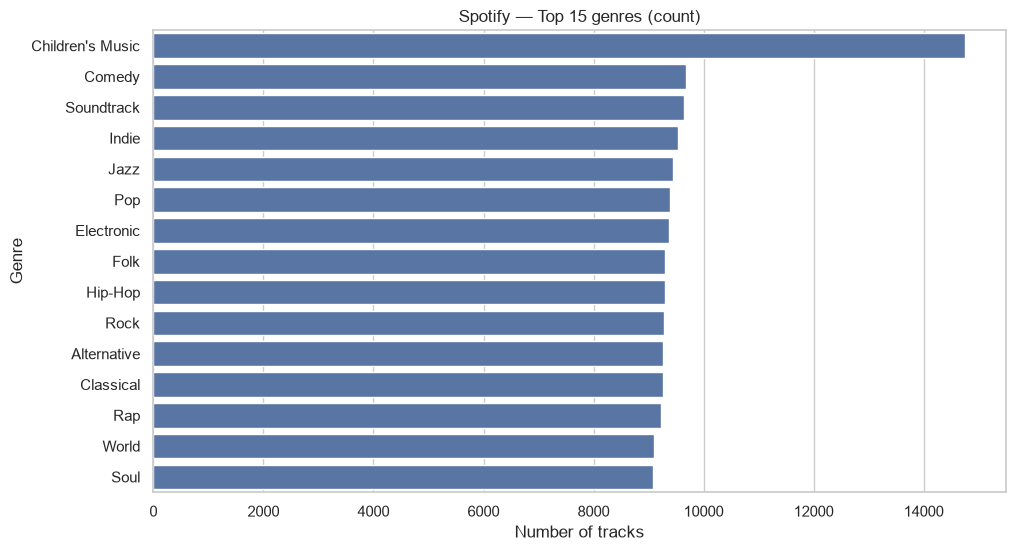

In [7]:
top_genres = spotify['genre'].value_counts().head(15)
plt.figure(figsize=(11,6))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Spotify — Top 15 genres (count)")
plt.xlabel("Number of tracks")
plt.ylabel("Genre")
plt.show()

Explore the distribution of snapshot popularity using one row per track ID.


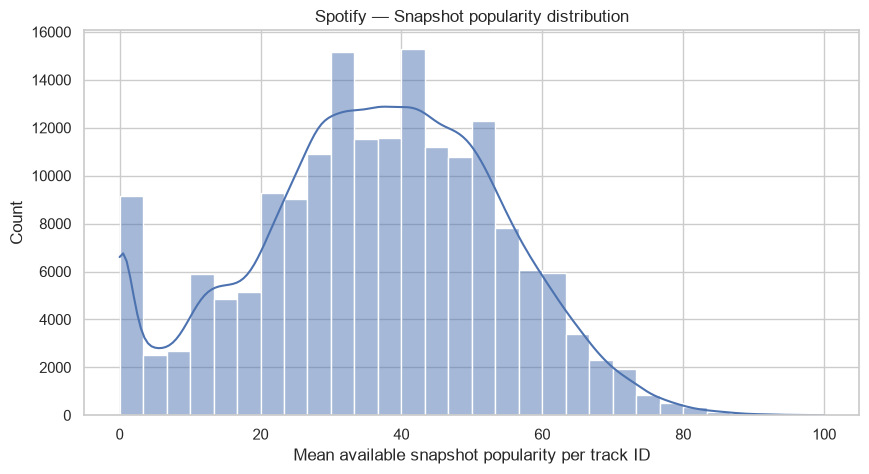

In [8]:
plt.figure(figsize=(10, 5))
sns.histplot(spotify_tracks["popularity"], bins=30, kde=True)
plt.title("Spotify — Snapshot popularity distribution")
plt.xlabel("Mean available snapshot popularity per track ID")
plt.show()


## 6) Spotify: audio feature distributions

Compare the ranges and shapes of eight audio features using one row per Spotify track ID.


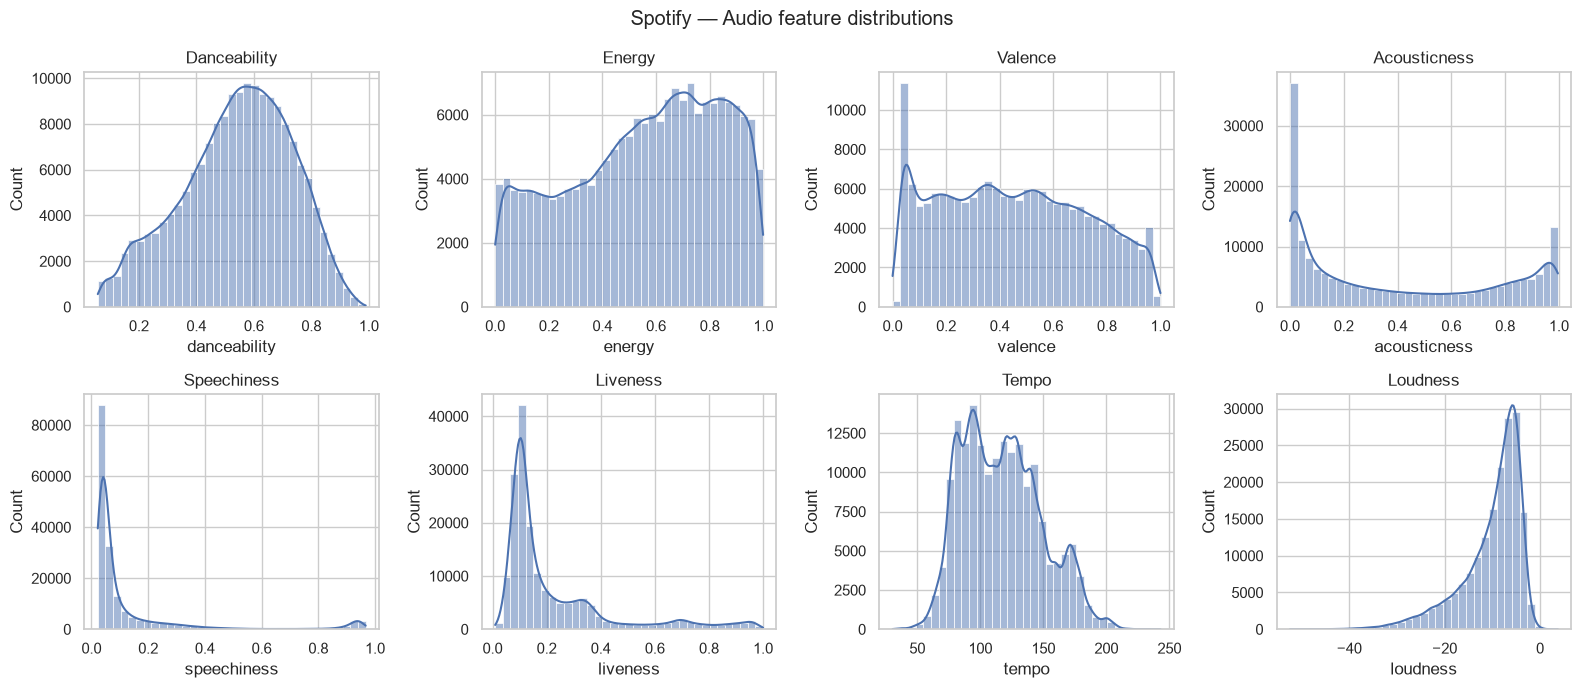

In [9]:
features = ["danceability", "energy", "valence", "acousticness",
            "speechiness", "liveness", "tempo", "loudness"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for feature, ax in zip(features, axes.flat):
    sns.histplot(spotify_tracks[feature], bins=35, kde=True, ax=ax)
    ax.set_title(feature.capitalize())
fig.suptitle("Spotify — Audio feature distributions")
plt.tight_layout()
plt.show()


Compute a correlation matrix for audio features (plus popularity) and show it as a heatmap to spot strong relationships.


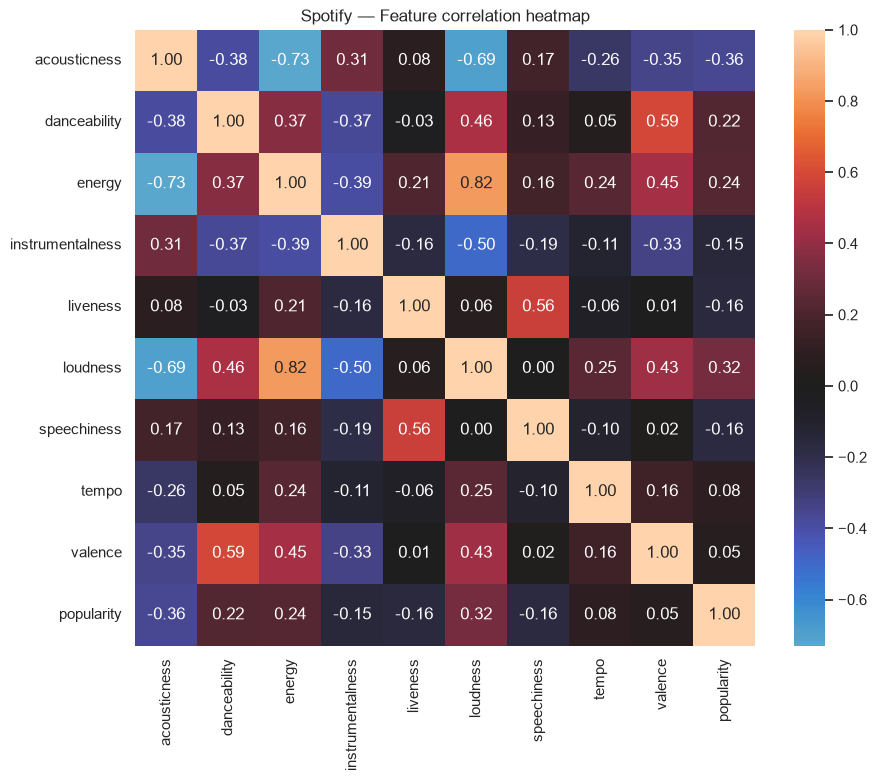

In [10]:
corr_cols = ["acousticness","danceability","energy","instrumentalness","liveness",
             "loudness","speechiness","tempo","valence","popularity"]

plt.figure(figsize=(10,8))
sns.heatmap(spotify_tracks[corr_cols].corr(), annot=True, fmt=".2f", center=0)
plt.title("Spotify — Feature correlation heatmap")
plt.show()


## 7) Spotify: “genre personalities” (which genres are most energetic / danceable / happy)

Compute average features per genre and retain groups with at least 50 distinct track IDs. Genre groups can overlap.


In [11]:
genre_stats = spotify.groupby('genre')[["danceability","energy","valence","tempo","loudness","popularity"]].mean()
genre_stats["count"] = spotify.groupby('genre').size()

genre_stats = genre_stats[genre_stats["count"] >= 50].copy()
genre_stats.sort_values("count", ascending=False).head()

,danceability,energy,valence,tempo,loudness,popularity,count
genre,,,,,,,
Children's Music,0.598829,0.593204,0.532251,121.638247,-8.399591,35.659972,14756
Comedy,0.559038,0.676094,0.412764,98.235488,-11.689321,21.342217,9681
Soundtrack,0.265616,0.221110,0.118483,104.083509,-19.282684,33.913971,9646
Indie,0.566821,0.581002,0.428665,119.290814,-7.915142,54.416531,9543
Jazz,0.585638,0.472776,0.508961,111.783658,-11.210457,40.735441,9441


Define a helper function that ranks genres by an average feature, then generate a few examples (energy, danceability, valence, popularity).


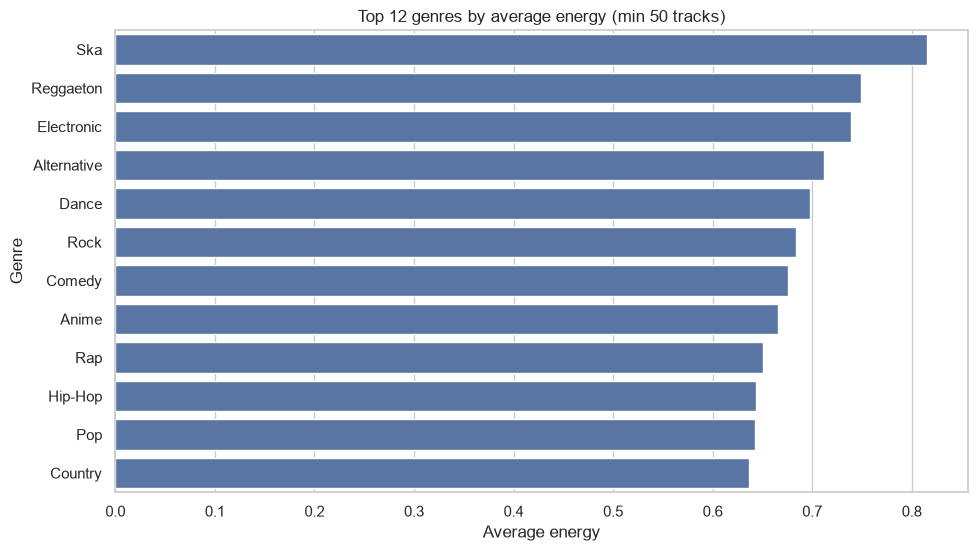

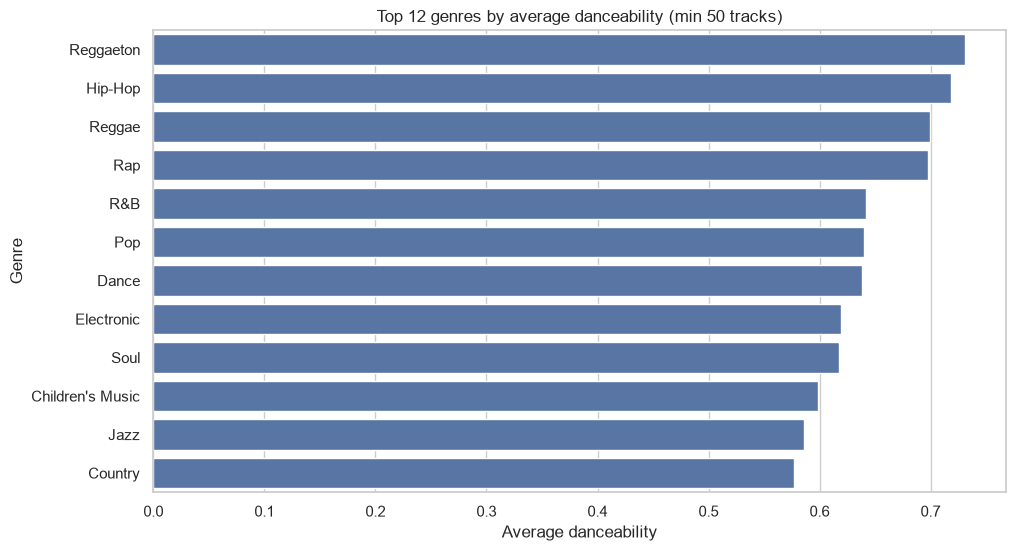

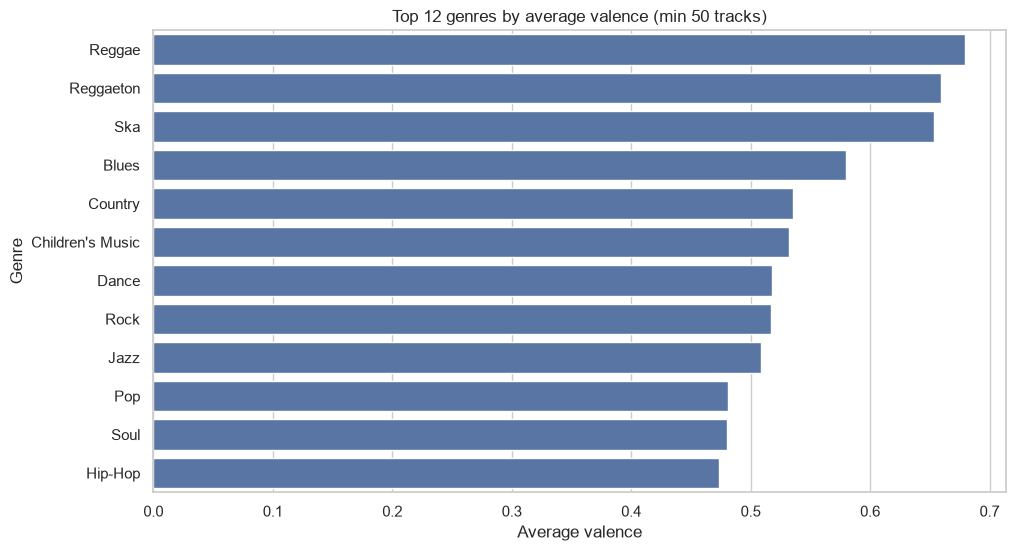

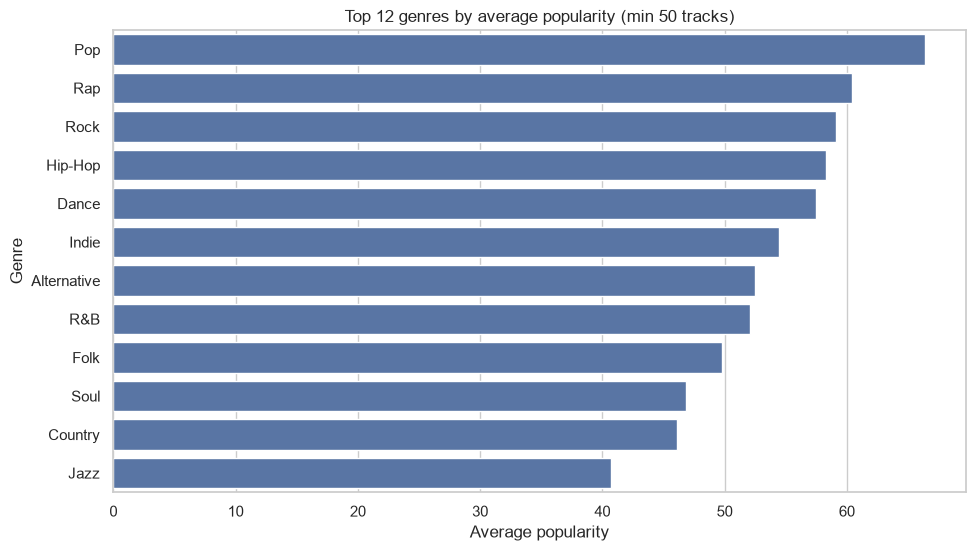

In [12]:
def plot_top_genres(feature, n=12, ascending=False):
    tmp = genre_stats.sort_values(feature, ascending=ascending).head(n)
    plt.figure(figsize=(11,6))
    sns.barplot(x=tmp[feature].values, y=tmp.index)
    plt.title(f"Top {n} genres by average {feature} (min 50 tracks)")
    plt.xlabel(f"Average {feature}")
    plt.ylabel("Genre")
    plt.show()

plot_top_genres("energy", 12, ascending=False)
plot_top_genres("danceability", 12, ascending=False)
plot_top_genres("valence", 12, ascending=False)
plot_top_genres("popularity", 12, ascending=False)

# PART 2 — Billboard Hot 100 dataset

## 8) Hot 100: time coverage

Check the earliest and latest chart dates and the number of chart weeks.


In [13]:
print("Min date:", hot100['chart_week'].min())
print("Max date:", hot100['chart_week'].max())
print("Unique weeks:", hot100['chart_week'].nunique())

Min date: 1958-08-04 00:00:00
Max date: 2024-06-08 00:00:00
Unique weeks: 3436


## 9) Hot 100: artists and songs that appear a lot

Count artist appearances in the Hot 100 and plot the top 15 by total rows.


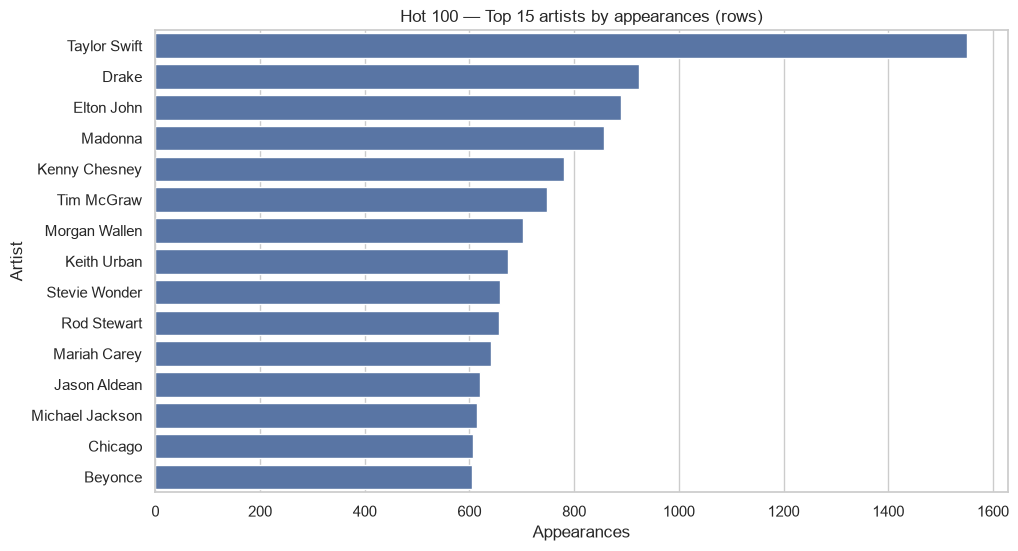

In [14]:
top_artists = hot100['performer'].value_counts().head(15)
plt.figure(figsize=(11,6))
sns.barplot(x=top_artists.values, y=top_artists.index)
plt.title("Hot 100 — Top 15 artists by appearances (rows)")
plt.xlabel("Appearances")
plt.ylabel("Artist")
plt.show()

Find song–artist pairs with the most Hot 100 rows (a proxy for weeks on the chart) and plot the top 15.


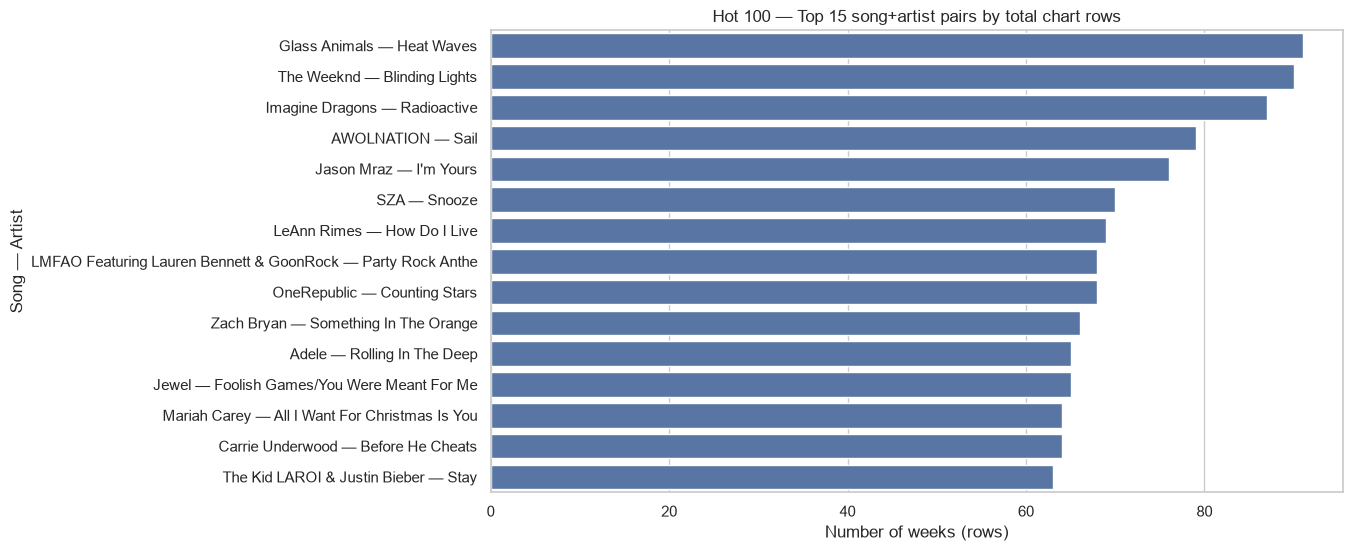

In [15]:
top_songs = hot100.groupby(['title', 'performer']).size().sort_values(ascending=False).head(15)
plt.figure(figsize=(11,6))
sns.barplot(x=top_songs.values, y=[f"{a} — {s}"[:60] for (s,a) in top_songs.index])
plt.title("Hot 100 — Top 15 song+artist pairs by total chart rows")
plt.xlabel("Number of weeks (rows)")
plt.ylabel("Song — Artist")
plt.show()

# PART 3 — Combine the datasets (Spotify × Hot 100)

## 10) Matching songs between datasets

Normalize case, punctuation and spacing while preserving accents, full artist credits and recording-version words. Match only keys identifying one Spotify track ID.


In [16]:
merged, matched = match_songs(hot100, spotify_tracks)
keys = ["song_clean", "artist_clean"]
print(f"Matched chart rows: {len(matched):,}/{len(merged):,} ({len(matched) / len(merged):.2%})")
matched.head(3)


Matched chart rows: 108,084/343,529 (31.46%)


,chart_week,current_week,title,performer,last_week,peak_pos,wks_on_chart,year,decade,song_clean,artist_clean,genre,artist_name,track_name,track_id,popularity,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,identity_consistent,genres
0,1964-07-04,1,I Get Around,The Beach Boys,2.0,1,7,1964,1960,i get around,the beach boys,Folk,The Beach Boys,I Get Around,3mXexrmtPJ1KdWN37rYePx,44.000000,0.320,0.388,133760.0,0.630,0.000000,A,0.0738,-6.292,Minor,0.0452,145.927,4/4,0.774,True,[Folk]
1,1988-07-16,1,The Flame,Cheap Trick,1.0,1,15,1988,1980,the flame,cheap trick,Dance,Cheap Trick,The Flame,528CAH5pTLq86oZ52fHifA,63.500000,0.513,0.629,338800.0,0.581,0.000002,E,0.0755,-11.856,Major,0.0270,97.074,4/4,0.359,True,"[Dance, Rock]"
2,1987-06-27,1,I Wanna Dance With Somebody (Who Loves Me),Whitney Houston,3.0,1,7,1987,1980,i wanna dance with somebody who loves me,whitney houston,Dance,Whitney Houston,I Wanna Dance with Somebody (Who Loves Me),2tUBqZG2AbRi7Q0BIrVrEj,82.666667,0.207,0.709,291293.0,0.824,0.000307,C#,0.0888,-8.824,Major,0.0453,118.814,4/4,0.867,True,"[Dance, Pop, R&B]"


## 11) Match quality and analysis units

Report unique-song coverage overall and by chart decade, and inspect example pairs. Define one best-ranked row per recording for song-level comparisons.


In [17]:
unique_total = merged[keys].drop_duplicates().shape[0]
unique_matched = matched[keys].drop_duplicates().shape[0]
print(f"Unique matched songs: {unique_matched:,}/{unique_total:,} ({unique_matched / unique_total:.2%})")
coverage = merged.drop_duplicates(keys + ["decade"]).groupby("decade")["track_id"].agg(total="size", matched="count")
coverage["match_rate"] = coverage["matched"] / coverage["total"]
display(coverage)
display(matched[['title', 'performer', 'track_name', 'artist_name']].drop_duplicates().head(10))

song_best = matched.sort_values(['current_week', 'chart_week']).drop_duplicates("track_id").copy()
song_best["rank_bucket"] = pd.cut(song_best['current_week'], [0, 10, 50, 100], labels=["Top 10", "11-50", "51-100"])
matched_decade = matched.drop_duplicates(["track_id", "decade"])


Unique matched songs: 6,922/31,327 (22.10%)


,total,matched,match_rate
decade,,,
1950,924,59,0.063853
1960,6954,661,0.095053
1970,5404,969,0.179312
1980,4220,758,0.179621
1990,3527,877,0.248653
2000,3516,1633,0.464448
2010,4580,2150,0.469432
2020,3024,61,0.020172


,title,performer,track_name,artist_name
0,I Get Around,The Beach Boys,I Get Around,The Beach Boys
1,The Flame,Cheap Trick,The Flame,Cheap Trick
2,I Wanna Dance With Somebody (Who Loves Me),Whitney Houston,I Wanna Dance with Somebody (Who Loves Me),Whitney Houston
3,Shadow Dancing,Andy Gibb,Shadow Dancing,Andy Gibb
6,Firework,Katy Perry,Firework,Katy Perry
9,Me And Mrs. Jones,Billy Paul,Me and Mrs. Jones,Billy Paul
11,How You Remind Me,Nickelback,How You Remind Me,Nickelback
13,Grenade,Bruno Mars,Grenade,Bruno Mars
14,Running Bear,Johnny Preston,Running Bear,Johnny Preston
16,Nice For What,Drake,Nice For What,Drake


# PART 4 — Combined analysis

## 12) Decade trends

Each Spotify ID contributes once per chart decade. Read the coverage table alongside these averages.


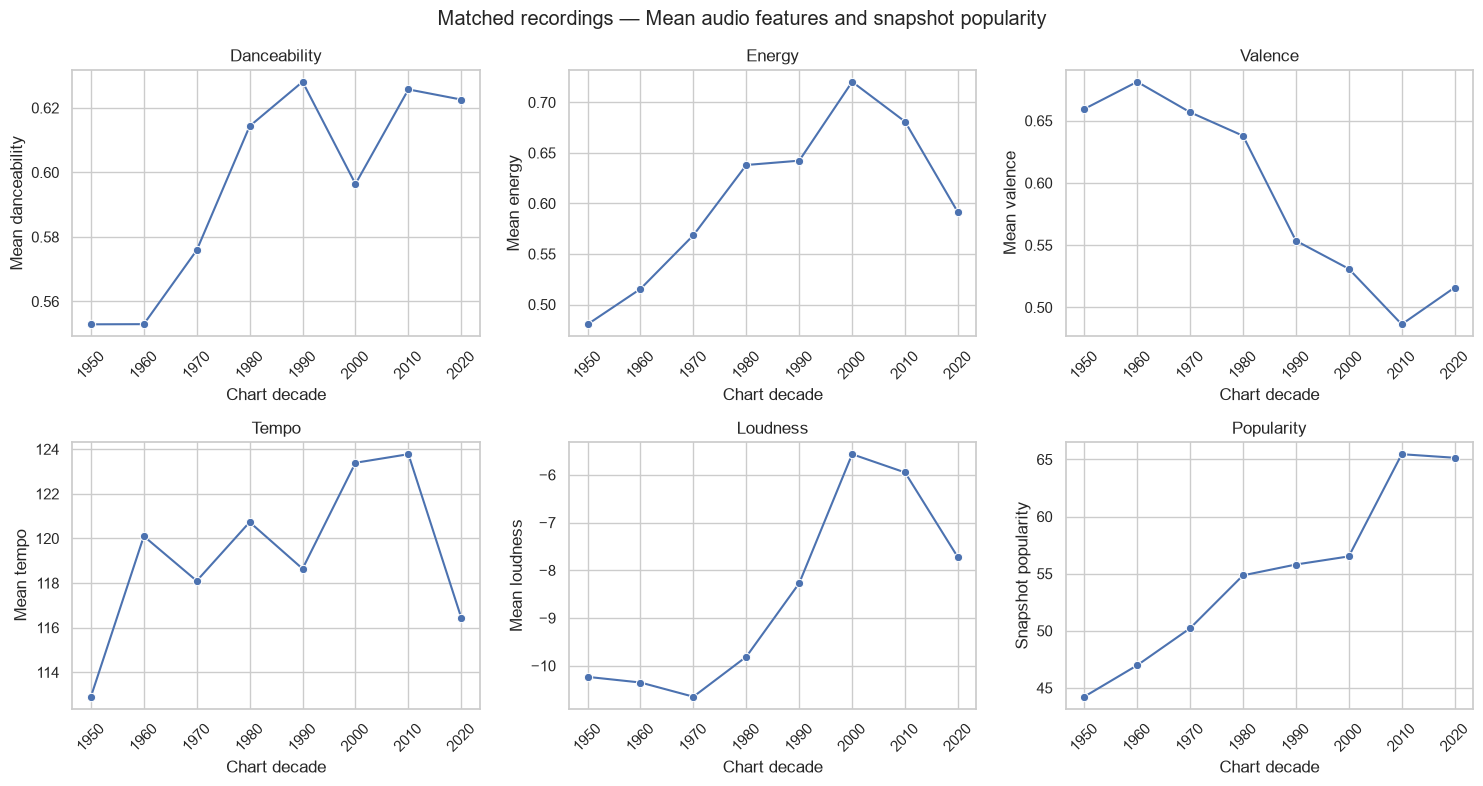

In [18]:
trend_features = ["danceability", "energy", "valence", "tempo", "loudness", "popularity"]
trend = matched_decade.groupby("decade")[trend_features].mean().reset_index()
trend_figure, axes = plt.subplots(2, 3, figsize=(15, 8))
for feature, ax in zip(trend_features, axes.flat):
    sns.lineplot(data=trend, x="decade", y=feature, marker="o", ax=ax)
    ax.set(title=feature.capitalize(), xlabel="Chart decade",
           ylabel="Snapshot popularity" if feature == "popularity" else f"Mean {feature}")
    ax.tick_params(axis="x", rotation=45)
trend_figure.suptitle("Matched recordings — Mean audio features and snapshot popularity")
plt.tight_layout()
plt.show()


## 13) Best observed chart rank

Each recording belongs to one peak-rank group. Compare distributions and medians, including the Top 10 minus 51–100 median difference.


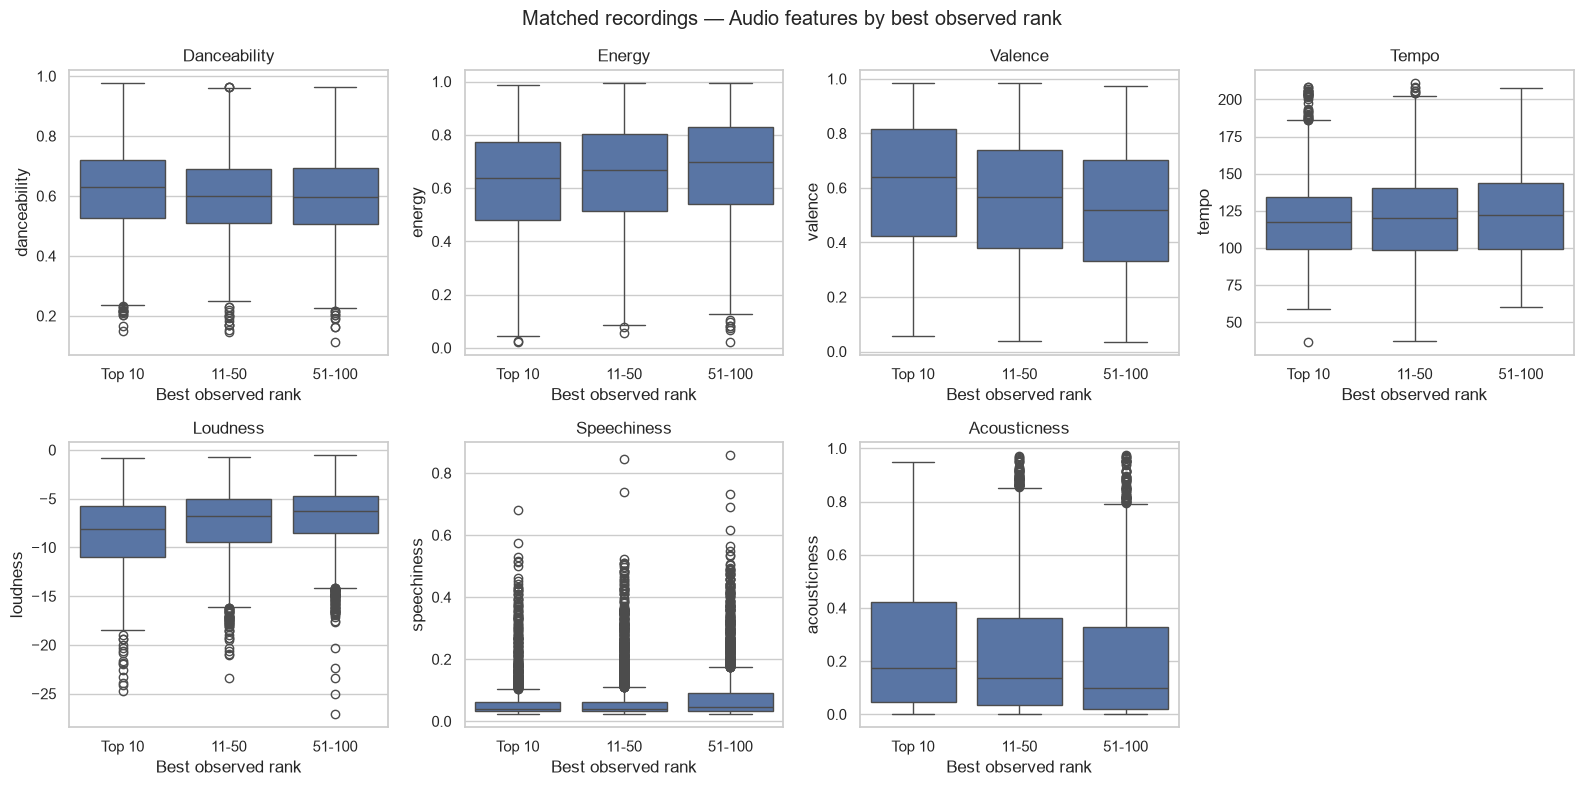

rank_bucket
Top 10    1980
11-50     2735
51-100    2207
Name: Recordings, dtype: int64

rank_bucket,Top 10,11-50,51-100,Top 10 minus 51-100
danceability,0.6310,0.5990,0.5980,0.0330
energy,0.6390,0.6670,0.6990,-0.0600
valence,0.6405,0.5660,0.5190,0.1215
tempo,117.4790,119.9890,121.9830,-4.5040
loudness,-8.1475,-6.7310,-6.2290,-1.9185
speechiness,0.0394,0.0403,0.0463,-0.0069
acousticness,0.1750,0.1370,0.1000,0.0750


In [19]:
compare = ["danceability", "energy", "valence", "tempo", "loudness", "speechiness", "acousticness"]
comparison_figure, axes = plt.subplots(2, 4, figsize=(16, 8))
for feature, ax in zip(compare, axes.flat):
    sns.boxplot(data=song_best, x="rank_bucket", y=feature, ax=ax)
    ax.set(title=feature.capitalize(), xlabel="Best observed rank", ylabel=feature)
axes.flat[-1].set_visible(False)
comparison_figure.suptitle("Matched recordings — Audio features by best observed rank")
plt.tight_layout()
plt.show()

medians = song_best.groupby("rank_bucket", observed=False)[compare].median()
median_comparison = medians.T.copy()
median_comparison["Top 10 minus 51-100"] = medians.loc["Top 10"] - medians.loc["51-100"]
display(song_best["rank_bucket"].value_counts(sort=False).rename("Recordings"))
display(median_comparison)


## 14) Relationships between audio features and snapshot popularity

Plot one point per recording: valence versus snapshot popularity, grouped by best observed rank.


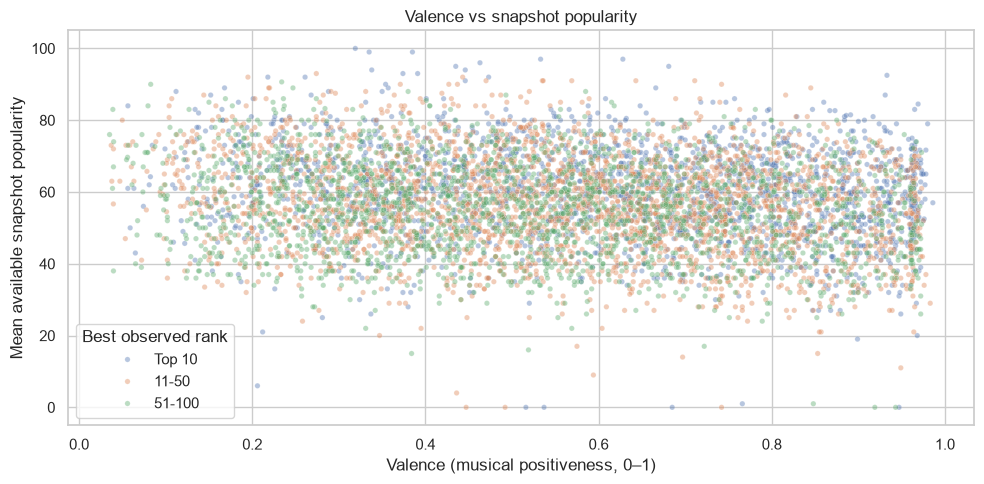

In [20]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=song_best, x="valence", y="popularity",
                hue="rank_bucket", alpha=0.4, s=15)
plt.title("Valence vs snapshot popularity")
plt.xlabel("Valence (musical positiveness, 0–1)")
plt.ylabel("Mean available snapshot popularity")
plt.legend(title="Best observed rank")
plt.tight_layout()
plt.show()


Plot danceability versus energy, with one point per recording.


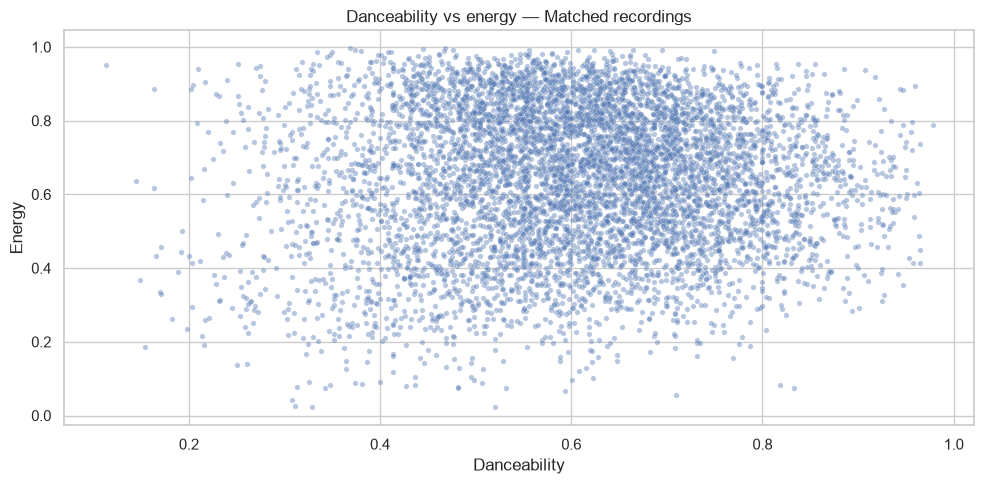

In [21]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=song_best, x="danceability", y="energy", alpha=0.4, s=15)
plt.title("Danceability vs energy — Matched recordings")
plt.xlabel("Danceability")
plt.ylabel("Energy")
plt.tight_layout()
plt.show()


Plot tempo versus loudness, grouped by the chart decade of each recording's best observed rank.


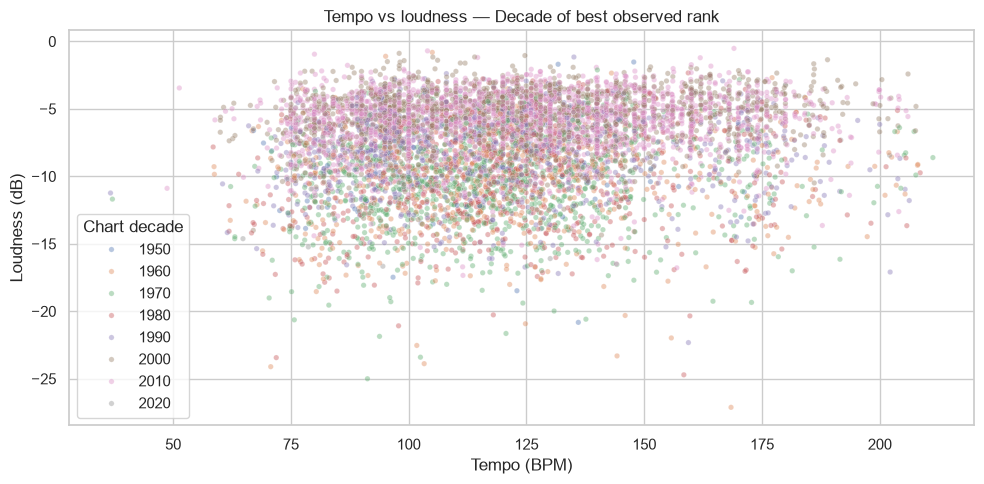

In [22]:
tempo_loudness = song_best.dropna(subset=["tempo", "loudness"]).copy()
tempo_loudness["chart_decade"] = tempo_loudness["decade"].astype(str)
plt.figure(figsize=(10, 5))
sns.scatterplot(data=tempo_loudness, x="tempo", y="loudness",
                hue="chart_decade", alpha=0.4, s=15)
plt.title("Tempo vs loudness — Decade of best observed rank")
plt.xlabel("Tempo (BPM)")
plt.ylabel("Loudness (dB)")
plt.legend(title="Chart decade")
plt.tight_layout()
plt.show()


## 15) Genres in the matched sample
Count each recording once. If a recording has several genre labels, divide its contribution equally between them. These are sample counts, not genre market shares.


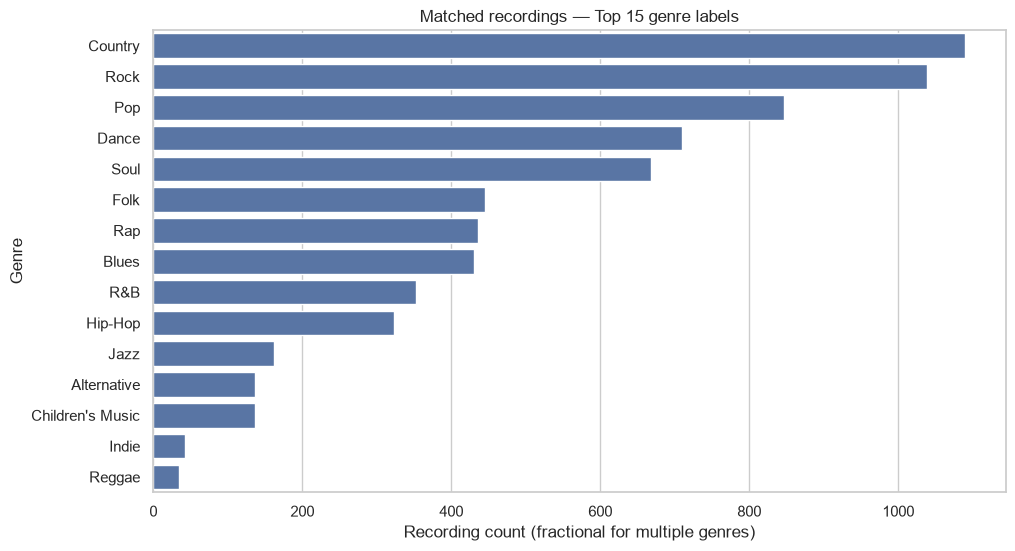

In [23]:
genre_songs = song_best[["track_id", "genres"]].copy()
genre_songs["weight"] = 1 / genre_songs["genres"].str.len()
genre_songs = genre_songs.explode("genres")
top_g = genre_songs.groupby("genres")["weight"].sum().nlargest(15)
plt.figure(figsize=(11, 6))
sns.barplot(x=top_g.values, y=top_g.index)
plt.title("Matched recordings — Top 15 genre labels")
plt.xlabel("Recording count (fractional for multiple genres)")
plt.ylabel("Genre")
plt.show()


## 16) Genre × Decade shares
Use all matched recording–decade observations as the denominator. A multi-genre recording contributes a total weight of one. Show the top 12 labels plus the remaining share.


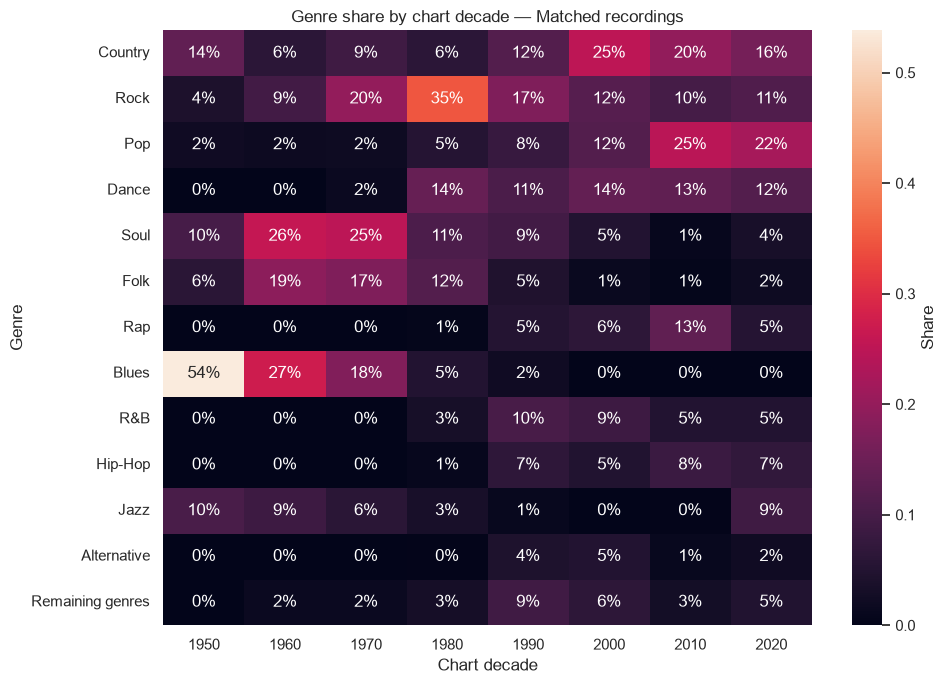

In [24]:
genre_decade = matched_decade[["track_id", "decade", "genres"]].copy()
genre_decade["weight"] = 1 / genre_decade["genres"].str.len()
genre_decade = genre_decade.explode("genres")
counts = genre_decade.pivot_table(index="genres", columns="decade", values="weight", aggfunc="sum", fill_value=0)
share = counts / counts.sum(axis=0)
top_genre_labels = counts.sum(axis=1).nlargest(12).index
plot_share = share.loc[top_genre_labels].copy()
plot_share.loc["Remaining genres"] = 1 - plot_share.sum(axis=0)

plt.figure(figsize=(10, 7))
sns.heatmap(plot_share, annot=True, fmt=".0%", cbar_kws={"label": "Share"})
plt.title("Genre share by chart decade — Matched recordings")
plt.xlabel("Chart decade")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


## 17) Example recordings

Show up to 12 recordings per rule: valence ≤ 0.20 and snapshot popularity ≥ 70; or tempo ≤ 80 BPM and a Top 10 peak.


In [25]:
low_valence_popular = song_best.loc[(song_best["valence"] <= 0.20) & (song_best["popularity"] >= 70)]
low_valence_popular = low_valence_popular.sort_values(["popularity", "valence"], ascending=[False, True])
print("Low valence and high snapshot popularity:")
display(low_valence_popular.head(12)[['title', 'performer', 'current_week', "valence", "popularity", "energy", "danceability"]])

slow_top10 = song_best.loc[(song_best['current_week'] <= 10) & (song_best["tempo"] <= 80)]
slow_top10 = slow_top10.sort_values("tempo")
print("Slow estimated tempo and an observed Top 10 peak:")
display(slow_top10.head(12)[['title', 'performer', 'current_week', "tempo", "popularity", "energy", "valence"]])


Low valence and high snapshot popularity:


,title,performer,current_week,valence,popularity,energy,danceability
46253,Needy,Ariana Grande,14,0.1950,92.0,0.309,0.647
188999,Bad Liar,Imagine Dragons,56,0.0827,90.0,0.637,0.383
250,Perfect,Ed Sheeran,1,0.1680,89.0,0.448,0.599
25536,Better,Khalid,8,0.1120,88.0,0.552,0.596
85368,Yosemite,Travis Scott,25,0.1440,87.0,0.554,0.785
23294,Youngblood,5 Seconds Of Summer,7,0.1520,87.0,0.854,0.596
155102,Pure Cocaine,Lil Baby,46,0.1070,86.0,0.487,0.964
286095,Ocean Eyes,Billie Eilish,84,0.1690,86.0,0.363,0.511
317829,Solo de Mi,Bad Bunny,93,0.1500,85.0,0.730,0.743
5111,Stay With Me,Sam Smith,2,0.1840,85.0,0.420,0.418


Slow estimated tempo and an observed Top 10 peak:


,title,performer,current_week,tempo,popularity,energy,valence
3572,If I Ever Fall In Love,Shai,2,36.710,57.000000,0.221,0.4150
26624,Both Sides Now,Judy Collins,8,58.686,50.000000,0.300,0.2950
11689,Birthday Sex,Jeremih,4,60.048,69.800000,0.545,0.4450
21216,A Bay Bay,Hurricane Chris,7,60.709,52.000000,0.668,0.7020
113,Where Do Broken Hearts Go,Whitney Houston,1,61.868,65.666667,0.386,0.2510
773,Hello,Lionel Richie,1,61.881,61.000000,0.244,0.0563
14227,One,Three Dog Night,5,62.130,55.750000,0.412,0.3950
3111,You Needed Me,Anne Murray,1,62.204,53.500000,0.296,0.1710
11180,Differences,Ginuwine,4,62.876,70.833333,0.594,0.4230
25697,interlude,J. Cole,8,64.825,52.000000,0.285,0.1570


## Key findings

These descriptive summaries are calculated from the current run. Interpret them alongside the coverage table and limits below.


In [26]:
print(f"Matched coverage: {unique_matched:,}/{unique_total:,} unique song–artist keys ({unique_matched / unique_total:.1%}).")
print(f"1. Across {len(trend)} represented chart decades, mean energy ranges from "
      f"{trend['energy'].min():.2f} to {trend['energy'].max():.2f}.")
if medians.loc[["Top 10", "51-100"], "energy"].notna().all():
    print(f"2. Median energy: Top 10 = {medians.loc['Top 10', 'energy']:.2f}; "
          f"51–100 = {medians.loc['51-100', 'energy']:.2f}; "
          f"difference = {median_comparison.loc['energy', 'Top 10 minus 51-100']:.2f}.")
else:
    print("2. Median energy comparison unavailable: one rank group has no valid energy measurements.")
print(f"3. Most represented matched genre label: {top_g.index[0]} "
      f"({top_g.iloc[0]:.1f} fractionally weighted recordings).")
print(f"4. Threshold examples: {len(low_valence_popular):,} low-valence/high-popularity recordings "
      f"and {len(slow_top10):,} slow-tempo recordings with a Top 10 peak.")


Matched coverage: 6,922/31,327 unique song–artist keys (22.1%).
1. Across 8 represented chart decades, mean energy ranges from 0.48 to 0.72.
2. Median energy: Top 10 = 0.64; 51–100 = 0.70; difference = -0.06.
3. Most represented matched genre label: Country (1090.0 fractionally weighted recordings).
4. Threshold examples: 131 low-valence/high-popularity recordings and 117 slow-tempo recordings with a Top 10 peak.


## Interpretation limits

Results describe the matched sample, whose coverage differs by chart decade. The 1950s cover only 1958–59, and boundary decades can be incomplete. Chart decade means chart presence, not release date. Genre and artist composition can also affect comparisons.

Matching full artist credits can miss collaborations credited differently across sources. Ambiguous recordings stay unmatched; matching names does not verify historical recording versions.

Popularity is the mean of available source-row values for each track ID, calculated before genre deduplication. It summarizes undated snapshot values rather than a verified score from one date, historical chart success, or necessarily current popularity. Other track-level fields use the first retained row.

Valence is musical positiveness, not a direct measure of listener mood. The plots, median differences and threshold examples are descriptive; they do not establish causes or statistical significance.


## Export results

Save the two summary figures and refresh the README findings from this run. Save the notebook afterward to retain its outputs.


In [27]:
figures_dir = PROJECT_ROOT / "figures"
figures_dir.mkdir(exist_ok=True)
trend_figure.savefig(figures_dir / "decade_trends.png", dpi=150, bbox_inches="tight")
comparison_figure.savefig(figures_dir / "rank_comparison.png", dpi=150, bbox_inches="tight")
energy_difference = median_comparison.loc["energy", "Top 10 minus 51-100"]
difference_text = "unavailable (missing group data)" if pd.isna(energy_difference) else f"{energy_difference:+.3f}"
findings = (
    f"- Matched **{unique_matched:,}/{unique_total:,}** unique song–artist keys (**{unique_matched / unique_total:.1%}**).\n"
    f"- Top 10 minus 51–100 median energy: **{difference_text}** (descriptive difference).\n"
    f"- Most represented matched genre: **{top_g.index[0]}**, with **{top_g.iloc[0]:.1f}** weighted recordings.\n\n"
    "![Decade trends](figures/decade_trends.png)\n\n"
    "![Rank comparisons](figures/rank_comparison.png)\n"
)
readme_path = PROJECT_ROOT / "README.md"
readme = readme_path.read_text(encoding="utf-8")
start, end = "<!-- RESULTS_START -->", "<!-- RESULTS_END -->"
before, after = readme.split(start, 1)[0], readme.split(end, 1)[1]
readme_path.write_text(f"{before}{start}\n{findings}{end}{after}", encoding="utf-8")
print("Saved two figures and refreshed README findings. Save this notebook to keep its outputs.")


Saved two figures and refreshed README findings. Save this notebook to keep its outputs.
